<a href="https://colab.research.google.com/github/Apur52027/depression_detection/blob/main/EDA_Depressionshort.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# 1. Load data
df= pd.read_excel('https://github.com/Apur52027/Dataset_ML/blob/main/BSMDD_v3_textcleaned%20-%2021K.xlsx?raw=true')

In [ ]:
# ============================================================
# CELL 0 — INSTALLATION
# ============================================================

!pip install -q pandas numpy matplotlib seaborn scipy scikit-learn statsmodels
!pip install -q nltk wordcloud
!pip install -q bangla-render

import warnings
warnings.filterwarnings("ignore")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.1/175.1 MB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.1/80.1 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.4/272.4 kB 21.4 MB/s eta 0:00:00


In [ ]:
# ============================================================
# CELL 1 — IMPORT LIBRARIES
# ============================================================

import os
import re
import math
import json
import string
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter, defaultdict

from scipy import stats
from scipy.stats import (
    chi2_contingency,
    mannwhitneyu,
    spearmanr
)

from statsmodels.stats.multitest import multipletests

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import silhouette_score

import nltk
from nltk.corpus import stopwords

import bangla_render as br

# Initialize Bengali renderer
br.init_renderer()

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================================
# CHANGE THIS PATH
# ============================================================

DATA_PATH = 'https://github.com/Apur52027/Dataset_ML/blob/main/BSMDD_v3_textcleaned%20-%2021K.xlsx?raw=true'

df = pd.read_excel(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (21910, 2)


,text,label
0,মানসিক শারীরিকভাবে অসুস্থ ক্লান্ত পুরো জীবন শা...,1
1,দয়া সাথে থাকুন অত্যন্ত দীর্ঘ আপনাকে পড়তে উত্...,1
2,জানতাম সাথে ভুল লোক খারাপ জীবন কাটিয়েছে সম্পূ...,1
3,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,1
4,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,1



Columns:
['text', 'label']


In [ ]:
# ============================================================
# CELL 3 — AUTOMATIC COLUMN DETECTION
# ============================================================

print("Available columns:")
print(df.columns.tolist())

text_candidates = [
    "text", "Text", "TEXT",
    "post", "Post",
    "sentence", "Sentence",
    "content", "Content",
    "comment", "Comment",
    "tweet", "Tweet",
    "review", "Review"
]

label_candidates = [
    "label", "Label", "LABEL",
    "class", "Class",
    "target", "Target",
    "category", "Category",
    "depression", "Depression",
    "status", "Status"
]

TEXT_COL = None
LABEL_COL = None

# Search text column
for col in text_candidates:
    if col in df.columns:
        TEXT_COL = col
        break

# Search label column
for col in label_candidates:
    if col in df.columns:
        LABEL_COL = col
        break

# Fallback: longest average string column
if TEXT_COL is None:
    string_cols = df.select_dtypes(include="object").columns

    if len(string_cols) > 0:
        avg_lengths = {
            col: df[col].astype(str).str.len().mean()
            for col in string_cols
        }

        TEXT_COL = max(avg_lengths, key=avg_lengths.get)

# Fallback: low-cardinality column for label
if LABEL_COL is None:
    candidate_cols = []

    for col in df.columns:
        nunique = df[col].nunique()

        if 2 <= nunique <= 10:
            candidate_cols.append(col)

    if candidate_cols:
        LABEL_COL = candidate_cols[-1]

print("Detected text column :", TEXT_COL)
print("Detected label column:", LABEL_COL)

Available columns:
['text', 'label']
Detected text column : text
Detected label column: label


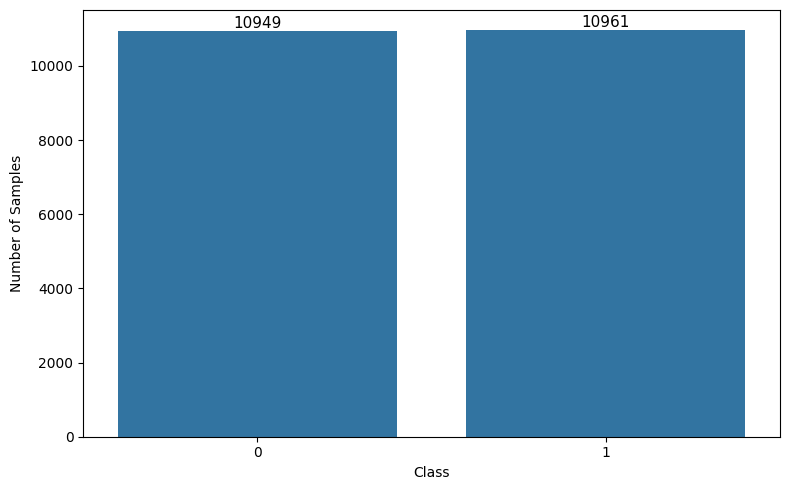

In [ ]:
# ============================================================
# CELL 5 — CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=LABEL_COL
)

# plt.title(
#     "Class Distribution",
#     fontsize=16,
#     fontweight="bold"
# )

plt.xlabel("Class")
plt.ylabel("Number of Samples")

# Add values
for container in ax.containers:
    ax.bar_label(container, fontsize=11)

plt.tight_layout()

plt.savefig(
    "figure_1_class_distribution.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from google.colab import files

files.download('figure_1_class_distribution.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# CELL 6 — DATA QUALITY
# ============================================================

# Ensure TEXT_COL and LABEL_COL are defined
# (These are typically set in an earlier cell like CkD_PgZD7g0-)
if 'TEXT_COL' not in globals():
    TEXT_COL = 'text'
if 'LABEL_COL' not in globals():
    LABEL_COL = 'label'

quality_report = pd.DataFrame({
    "Metric": [
        "Total samples",
        "Missing text",
        "Empty text",
        "Duplicate text",
        "Missing label",
        "Unique texts"
    ],
    "Count": [
        len(df),
        df[TEXT_COL].isna().sum(),
        (df[TEXT_COL].fillna("").astype(str).str.strip() == "").sum(),
        df[TEXT_COL].duplicated().sum(),
        df[LABEL_COL].isna().sum(),
        df[TEXT_COL].nunique()
    ]
})

display(quality_report)

,Metric,Count
0,Total samples,21910
1,Missing text,0
2,Empty text,0
3,Duplicate text,6
4,Missing label,0
5,Unique texts,21904


In [ ]:
# ============================================================
# CELL 7 — CLEAN BASIC INVALID TEXT
# ============================================================

eda_df = df.copy()

eda_df[TEXT_COL] = (
    eda_df[TEXT_COL]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Remove empty text
eda_df = eda_df[
    eda_df[TEXT_COL].str.len() > 0
].copy()

# Remove missing labels
eda_df = eda_df[
    eda_df[LABEL_COL].notna()
].copy()

eda_df.reset_index(drop=True, inplace=True)

print("Original samples:", len(df))
print("EDA samples     :", len(eda_df))

Original samples: 21910
EDA samples     : 21910


In [ ]:
# ============================================================
# CELL 8 — BANGLA TEXT NORMALIZATION
# ============================================================

BANGLA_RANGE = r"\u0980-\u09FF"

def normalize_bangla(text):

    text = str(text)

    # Unicode normalization
    import unicodedata
    text = unicodedata.normalize("NFC", text)

    # URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Mentions
    text = re.sub(r"@\w+", " ", text)

    # Hashtag symbol but retain word
    text = text.replace("#", " ")

    # English digits + Bengali digits
    text = re.sub(r"[0-9০-৯]+", " ", text)

    # Keep Bengali, English letters and whitespace
    text = re.sub(
        rf"[^{BANGLA_RANGE}A-Za-z\s]",
        " ",
        text
    )

    # Multiple spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()


eda_df["clean_text"] = eda_df[TEXT_COL].apply(normalize_bangla)

display(
    eda_df[[TEXT_COL, "clean_text"]].head(10)
)

,text,clean_text
0,মানসিক শারীরিকভাবে অসুস্থ ক্লান্ত পুরো জীবন শা...,মানসিক শারীরিকভাবে অসুস্থ ক্লান্ত পুরো জীবন শা...
1,দয়া সাথে থাকুন অত্যন্ত দীর্ঘ আপনাকে পড়তে উত্...,দয়া সাথে থাকুন অত্যন্ত দীর্ঘ আপনাকে পড়তে উত্...
2,জানতাম সাথে ভুল লোক খারাপ জীবন কাটিয়েছে সম্পূ...,জানতাম সাথে ভুল লোক খারাপ জীবন কাটিয়েছে সম্পূ...
3,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...
4,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...
5,প্রথমে আপনাকে প্রশ্ন উপস্থাপন যাচ্ছি পারবেন দি...,প্রথমে আপনাকে প্রশ্ন উপস্থাপন যাচ্ছি পারবেন দি...
6,রেফারেন্সের বয়সী পুরুষ থাকার সাইক ওয়ার্ড বের...,রেফারেন্সের বয়সী পুরুষ থাকার সাইক ওয়ার্ড বের...
7,দৈর্ঘ্যের ক্ষমাপ্রার্থী বোঝানোর বের আলিঙ্গন বল...,দৈর্ঘ্যের ক্ষমাপ্রার্থী বোঝানোর বের আলিঙ্গন বল...
8,উপকারী সাব দয়া আপলোড পোস্ট সেরা জায়গা মোবাইল...,উপকারী সাব দয়া আপলোড পোস্ট সেরা জায়গা মোবাইল...
9,দীর্ঘ পোস্ট জীবনের সারসংক্ষেপ টাইম লাইনটি একটু...,দীর্ঘ পোস্ট জীবনের সারসংক্ষেপ টাইম লাইনটি একটু...


In [ ]:
eda_df = df.copy()

print("Original number of rows:", eda_df.shape[0])

duplicate_rows = eda_df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_rows}")

if duplicate_rows > 0:
    eda_df.drop_duplicates(inplace=True)
    eda_df.reset_index(drop=True, inplace=True)
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found.")

print("Number of rows after removing duplicates:", eda_df.shape[0])
display(eda_df.head())

Original number of rows: 21910
Number of duplicate rows: 6
Duplicate rows removed.
Number of rows after removing duplicates: 21904


,text,label
0,মানসিক শারীরিকভাবে অসুস্থ ক্লান্ত পুরো জীবন শা...,1
1,দয়া সাথে থাকুন অত্যন্ত দীর্ঘ আপনাকে পড়তে উত্...,1
2,জানতাম সাথে ভুল লোক খারাপ জীবন কাটিয়েছে সম্পূ...,1
3,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,1
4,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,1


In [ ]:
import re
import unicodedata

# Ensure TEXT_COL is defined if not already in the context
if 'TEXT_COL' not in globals():
    TEXT_COL = 'text' # Assuming 'text' is the default if not detected

BANGLA_RANGE = r"\u0980-\u09FF"

def normalize_bangla(text):
    text = str(text)
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = text.replace("#", " ")
    text = re.sub(r"[0-9০-৯]+", " ", text)
    text = re.sub(rf"[^{BANGLA_RANGE}A-Za-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# Create clean_text if it doesn't exist
if "clean_text" not in eda_df.columns:
    eda_df["clean_text"] = eda_df[TEXT_COL].apply(normalize_bangla)

def tokenize(text):
    return re.findall(
        rf"[{BANGLA_RANGE}A-Za-z]+",
        str(text)
    )

eda_df["tokens"] = eda_df["clean_text"].apply(tokenize)

eda_df["word_count"] = eda_df["tokens"].apply(len)

print(eda_df["word_count"].describe())

count    21904.000000
mean        80.416271
std         60.481798
min          0.000000
25%         40.000000
50%         61.000000
75%        104.000000
max        704.000000
Name: word_count, dtype: float64


In [ ]:
# ============================================================
# CELL 10 — CHARACTER COUNT
# ============================================================

eda_df["char_count"] = (
    eda_df["clean_text"]
    .str.replace(r"\s+", "", regex=True)
    .str.len()
)

display(
    eda_df["char_count"].describe()
)

,char_count
count,21904.000000
mean,471.384861
std,361.714435
min,0.000000
25%,232.000000
50%,360.000000
75%,610.000000
max,4201.000000


In [ ]:
# ============================================================
# CELL 11 — UNIQUE WORD COUNT
# ============================================================

eda_df["unique_word_count"] = (
    eda_df["tokens"]
    .apply(lambda x: len(set(x)))
)

display(
    eda_df["unique_word_count"].describe()
)

,unique_word_count
count,21904.000000
mean,66.263057
std,45.364031
min,0.000000
25%,35.000000
50%,52.000000
75%,86.000000
max,494.000000


In [ ]:
# ============================================================
# CELL 12 — SENTENCE COUNT
# ============================================================

def sentence_count(text):

    text = str(text).strip()

    if not text:
        return 0

    sentences = re.split(
        r"[।!?]+",
        text
    )

    sentences = [
        s.strip()
        for s in sentences
        if s.strip()
    ]

    return len(sentences)


eda_df["sentence_count"] = (
    eda_df[TEXT_COL]
    .apply(sentence_count)
)

display(
    eda_df["sentence_count"].describe()
)

,sentence_count
count,21904.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0


In [ ]:
# ============================================================
# CELL 13 — TYPE TOKEN RATIO
# ============================================================

def calculate_ttr(tokens):

    if len(tokens) == 0:
        return 0

    return len(set(tokens)) / len(tokens)


eda_df["TTR"] = (
    eda_df["tokens"]
    .apply(calculate_ttr)
)

display(
    eda_df["TTR"].describe()
)

,TTR
count,21904.000000
mean,0.853730
std,0.090689
min,0.000000
25%,0.810811
50%,0.861111
75%,0.910112
max,1.000000


In [ ]:
import numpy as np
from collections import Counter

In [ ]:
# ============================================================
# CELL 14 — ADDITIONAL TEXT FEATURES
# ============================================================

def repetition_ratio(tokens):

    if len(tokens) == 0:
        return 0

    counts = Counter(tokens)

    repeated_tokens = sum(
        count - 1
        for count in counts.values()
        if count > 1
    )

    return repeated_tokens / len(tokens)


eda_df["repetition_ratio"] = (
    eda_df["tokens"]
    .apply(repetition_ratio)
)

eda_df["avg_word_length"] = (
    eda_df["tokens"]
    .apply(
        lambda x: np.mean([len(w) for w in x])
        if len(x) > 0 else 0
    )
)

display(
    eda_df[
        [
            "word_count",
            "char_count",
            "unique_word_count",
            "sentence_count",
            "TTR",
            "repetition_ratio",
            "avg_word_length"
        ]
    ].describe()
)

,word_count,char_count,unique_word_count,sentence_count,TTR,repetition_ratio,avg_word_length
count,21904.000000,21904.000000,21904.000000,21904.0,21904.000000,21904.000000,21904.000000
mean,80.416271,471.384861,66.263057,1.0,0.853730,0.146178,5.824845
std,60.481798,361.714435,45.364031,0.0,0.090689,0.090333,0.453910
min,0.000000,0.000000,0.000000,1.0,0.000000,0.000000,0.000000
25%,40.000000,232.000000,35.000000,1.0,0.810811,0.089888,5.547619
50%,61.000000,360.000000,52.000000,1.0,0.861111,0.138788,5.812834
75%,104.000000,610.000000,86.000000,1.0,0.910112,0.189189,6.090909
max,704.000000,4201.000000,494.000000,1.0,1.000000,0.996667,10.820000


In [ ]:
# ============================================================
# CELL 15 — LINGUISTIC STATISTICS
# ============================================================

feature_cols = [
    "word_count",
    "char_count",
    "unique_word_count",
    "sentence_count",
    "TTR",
    "repetition_ratio",
    "avg_word_length"
]

linguistic_summary = []

for feature in feature_cols:

    for label in sorted(
        eda_df[LABEL_COL].unique(),
        key=lambda x: str(x)
    ):

        values = eda_df.loc[
            eda_df[LABEL_COL] == label,
            feature
        ]

        linguistic_summary.append({
            "Feature": feature,
            "Class": label,
            "N": len(values),
            "Mean": values.mean(),
            "Median": values.median(),
            "Std": values.std(),
            "Min": values.min(),
            "Max": values.max()
        })

linguistic_summary = pd.DataFrame(
    linguistic_summary
)

display(linguistic_summary)

,Feature,Class,N,Mean,Median,Std,Min,Max
0,word_count,0,10947,80.694894,60.000000,47.656002,0.000000,493.000000
1,word_count,1,10957,80.137903,63.000000,71.020519,6.000000,704.000000
2,char_count,0,10947,475.296063,360.000000,285.579018,0.000000,2350.000000
3,char_count,1,10957,467.477229,361.000000,424.329700,36.000000,4201.000000
4,unique_word_count,0,10947,66.000457,52.000000,36.037880,0.000000,242.000000
5,unique_word_count,1,10957,66.525418,54.000000,53.069944,2.000000,494.000000
6,sentence_count,0,10947,1.000000,1.000000,0.000000,1.000000,1.000000
7,sentence_count,1,10957,1.000000,1.000000,0.000000,1.000000,1.000000
8,TTR,0,10947,0.840464,0.851852,0.099128,0.000000,1.000000
9,TTR,1,10957,0.866985,0.870968,0.079204,0.003333,1.000000


In [ ]:
# ============================================================
# CELL 20 — STATISTICAL TESTS
# ============================================================

labels = eda_df[LABEL_COL].unique()

print("Classes:", labels)

if len(labels) == 2:

    class_a = labels[0]
    class_b = labels[1]

    statistical_results = []

    for feature in feature_cols:

        x = eda_df.loc[
            eda_df[LABEL_COL] == class_a,
            feature
        ].dropna()

        y = eda_df.loc[
            eda_df[LABEL_COL] == class_b,
            feature
        ].dropna()

        stat, p = mannwhitneyu(
            x,
            y,
            alternative="two-sided"
        )

        # Rank-biserial correlation
        n1 = len(x)
        n2 = len(y)

        rank_biserial = (
            1 - (2 * stat) / (n1 * n2)
        )

        statistical_results.append({
            "Feature": feature,
            "Class_A": class_a,
            "Class_B": class_b,
            "Statistic": stat,
            "p_value": p,
            "Rank_Biserial": rank_biserial
        })

    statistical_results = pd.DataFrame(
        statistical_results
    )

    # FDR correction
    reject, p_adj, _, _ = multipletests(
        statistical_results["p_value"],
        method="fdr_bh"
    )

    statistical_results["FDR_p_value"] = p_adj
    statistical_results["Significant_FDR"] = reject

    display(statistical_results)

Classes: [1 0]


,Feature,Class_A,Class_B,Statistic,p_value,Rank_Biserial,FDR_p_value,Significant_FDR
0,word_count,1,0,51081925.5,1.634336e-80,0.148253,2.860089e-80,True
1,char_count,1,0,50760862.5,2.753605e-86,0.153607,6.425079e-86,True
2,unique_word_count,1,0,52701438.5,1.823215e-54,0.121249,2.127085e-54,True
3,sentence_count,1,0,59973139.5,1.000000e+00,0.000000,1.000000e+00,False
4,TTR,1,0,69551293.5,3.977025e-93,-0.159707,2.783917e-92,True
5,repetition_ratio,1,0,50416283.5,1.010865e-92,0.159352,3.538026e-92,True
6,avg_word_length,1,0,52299798.0,1.951856e-60,0.127946,2.732598e-60,True


In [ ]:
# ============================================================
# LINGUISTIC STATISTICAL ANALYSIS
# Mann–Whitney U + FDR + Rank-Biserial Effect Size
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. Linguistic features
# ------------------------------------------------------------

linguistic_features = [
    "word_count",
    "char_count",
    "TTR",
    "repetition_ratio"
]

# ------------------------------------------------------------
# 2. Separate groups
# ------------------------------------------------------------

non_depressed = eda_df[eda_df[LABEL_COL] == 0]
depressed = eda_df[eda_df[LABEL_COL] == 1]

print("Non-depressed:", len(non_depressed))
print("Depressed:", len(depressed))


# ------------------------------------------------------------
# 3. Mann–Whitney U + Rank-Biserial Effect Size
# ------------------------------------------------------------

results = []

for feature in linguistic_features:

    x = non_depressed[feature].dropna().values
    y = depressed[feature].dropna().values

    # Mann–Whitney U
    U, p = mannwhitneyu(
        x,
        y,
        alternative="two-sided"
    )

    # Rank-biserial correlation
    n1 = len(x)
    n2 = len(y)

    r_rb = 1 - (2 * U) / (n1 * n2)

    results.append({
        "Feature": feature,
        "Non-depressed Median": np.median(x),
        "Depressed Median": np.median(y),
        "Mann-Whitney U": U,
        "Raw p-value": p,
        "Rank-biserial r": r_rb
    })


results_df = pd.DataFrame(results)


# ------------------------------------------------------------
# 4. FDR correction
# ------------------------------------------------------------

reject, p_fdr, _, _ = multipletests(
    results_df["Raw p-value"],
    method="fdr_bh"
)

results_df["FDR-adjusted p"] = p_fdr
results_df["Significant"] = reject


# ------------------------------------------------------------
# 5. Effect-size interpretation
# ------------------------------------------------------------

def interpret_rank_biserial(r):

    abs_r = abs(r)

    if abs_r < 0.10:
        return "Negligible"

    elif abs_r < 0.30:
        return "Small"

    elif abs_r < 0.50:
        return "Moderate"

    else:
        return "Large"


results_df["Effect size"] = (
    results_df["Rank-biserial r"]
    .apply(interpret_rank_biserial)
)


# ------------------------------------------------------------
# 6. Formatting
# ------------------------------------------------------------

results_df["Mann-Whitney U"] = (
    results_df["Mann-Whitney U"]
    .round(2)
)

results_df["Non-depressed Median"] = (
    results_df["Non-depressed Median"]
    .round(3)
)

results_df["Depressed Median"] = (
    results_df["Depressed Median"]
    .round(3)
)

results_df["Rank-biserial r"] = (
    results_df["Rank-biserial r"]
    .round(4)
)

results_df["Raw p-value"] = (
    results_df["Raw p-value"]
    .apply(lambda x: f"{x:.3e}")
)

results_df["FDR-adjusted p"] = (
    results_df["FDR-adjusted p"]
    .apply(lambda x: f"{x:.3e}")
)


display(results_df)

Non-depressed: 10947
Depressed: 10957


,Feature,Non-depressed Median,Depressed Median,Mann-Whitney U,Raw p-value,Rank-biserial r,FDR-adjusted p,Significant,Effect size
0,word_count,60.000,63.000,68864353.5,1.634e-80,-0.1483,1.634e-80,True,Small
1,char_count,360.000,361.000,69185416.5,2.754e-86,-0.1536,3.671e-86,True,Small
2,TTR,0.852,0.871,50394985.5,3.977e-93,0.1597,1.591e-92,True,Small
3,repetition_ratio,0.148,0.129,69529995.5,1.011e-92,-0.1594,2.022e-92,True,Small


In [ ]:
#Mann–Whitney U
#Rank-biserial effect size

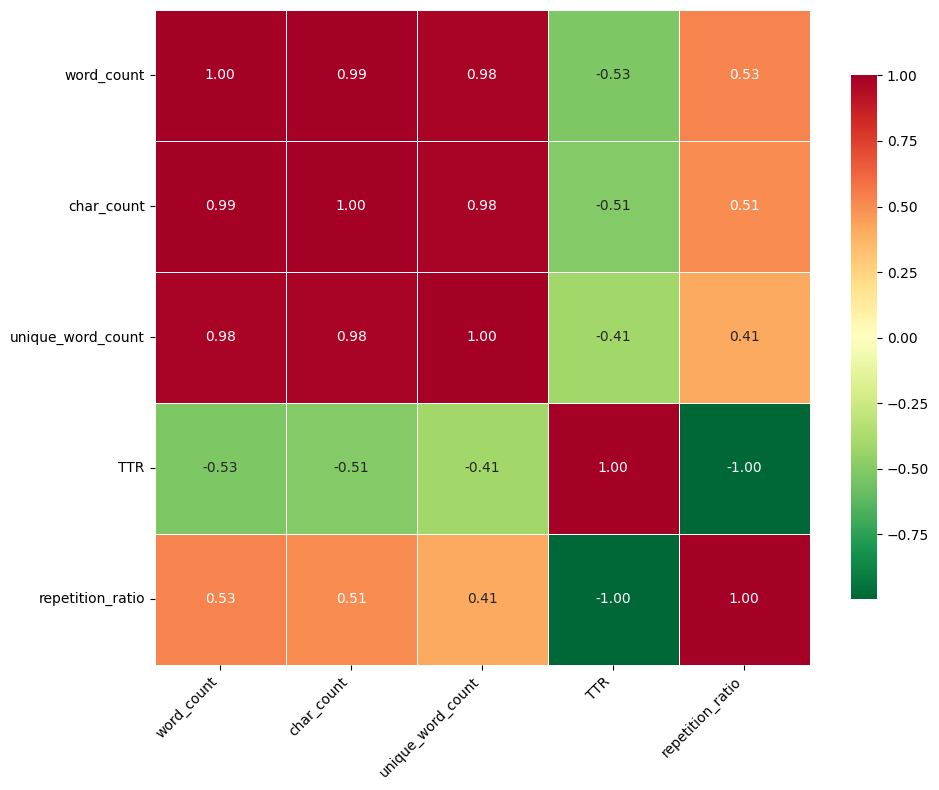

In [ ]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    center=0,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"shrink": 0.8}
)

# plt.title(
#     "Spearman Correlation Among Linguistic Features",
#     fontsize=16,
#     fontweight="bold"
# )

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "figure_6_spearman_correlation.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# CELL 23 — BANGLA STOPWORDS
# ============================================================

bangla_stopwords = set("""

আমি আমরা আমাদের আমার আমাকে
তুমি তোমরা তোমার তোমাদের তোমাকে
সে তারা তার তাদের তাকে
এই এইটা এইটি এইসব
ও ওই সেটা সেটি
এবং আর কিন্তু তবে
যে যা যার যাদের
কে কি কী
কেন কিভাবে
থেকে জন্য সঙ্গে সাথে
করে করা উঅ্যায়
হয় হয়নি হয়েছে
ছিল ছিলাম ছিলো ছিলআমি
আছে আছি আছেন আছেআমি
হয়েছে হবে বিআমি
এক একটি অনেক আম্প
খুব আরও আবার দিয়েছি
তো মিলিগ্রাম মপি স্থ পিঁ
""".split())

def remove_stopwords(tokens):
    return [
        token for token in tokens
        if token not in bangla_stopwords
        and len(token) > 1
    ]

eda_df["analysis_tokens"] = (
    eda_df["tokens"]
    .apply(remove_stopwords)
)

print("Stopwords:", len(bangla_stopwords))

Stopwords: 70


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  fonts-noto-mono
The following NEW packages will be installed:
  fonts-noto-core fonts-noto-mono
0 upgraded, 2 newly installed, 0 to remove and 33 not upgraded.
Need to get 13.7 MB of archives.
After this operation, 44.8 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 fonts-noto-mono all 20201225-2 [435 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/main amd64 fonts-noto-core all 20201225-2 [13.3 MB]
Fetched 13.7 MB in 2s (5,620 kB/s)
Selecting previously unselected package fonts-noto-mono.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../fonts-noto-mono_20201225-2_all.deb ...
Unpacking fonts-noto-mono (20201225-2) ...
Selecting previously unselected package fonts-noto-core.
Preparing to unpack .../fonts-noto-core_20201225-2_all.deb ...
Un

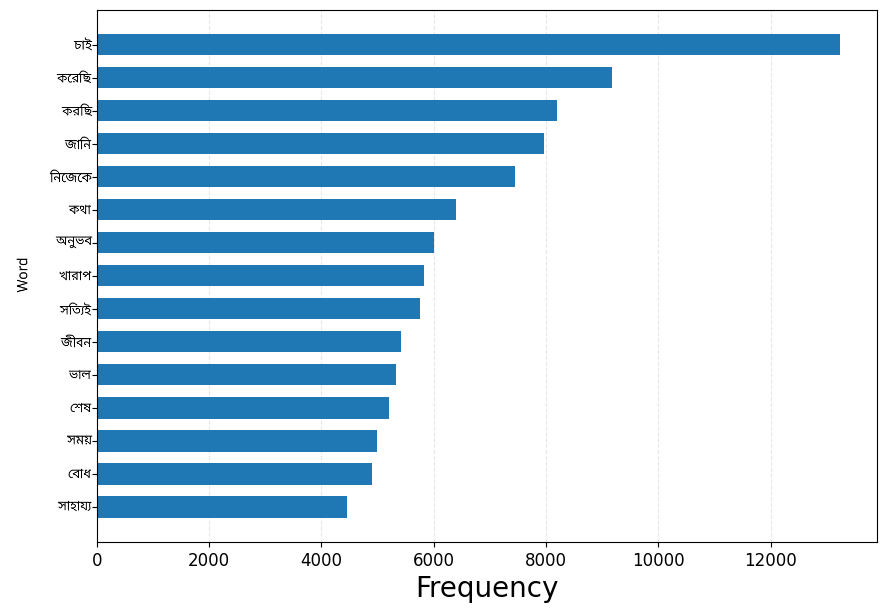

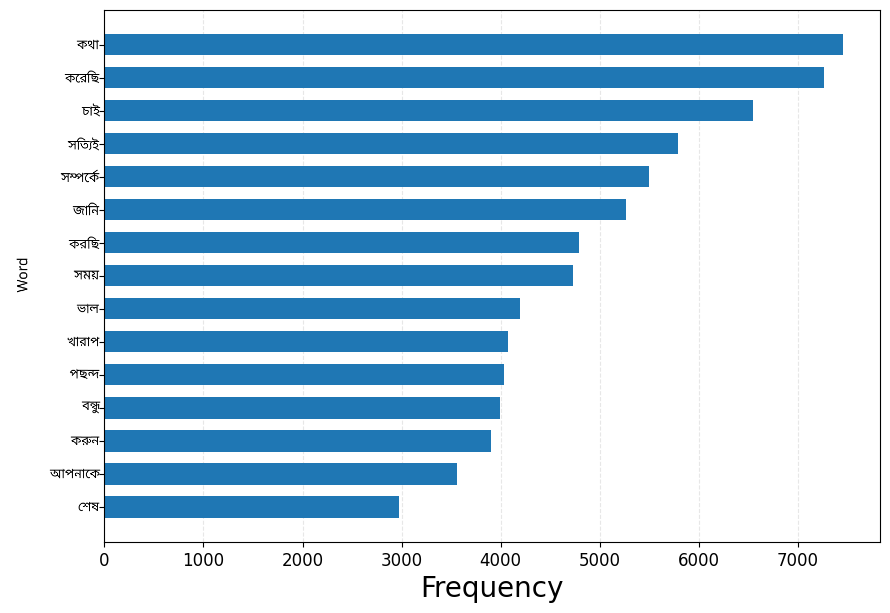

In [ ]:
# ============================================================
# CELL 26 — TOP WORDS HORIZONTAL BAR CHART
# WITH BANGLA RENDERING
# ============================================================


# ============================================================
# IMPORT
# ============================================================
import matplotlib.pyplot as plt
import bangla_render as br
import os
import matplotlib
import matplotlib.font_manager
import glob
import numpy as np
import pandas as pd


# ============================================================
# INSTALL NOTO SANS BENGALI FONT
# ============================================================
!apt-get install -y fonts-noto-core


# ============================================================
# FIND NOTO SANS BENGALI FONT
# ============================================================
font_files = glob.glob(
    '/usr/share/fonts/**/NotoSansBengali-Regular.ttf',
    recursive=True
)

if not font_files:
    raise FileNotFoundError(
        "NotoSansBengali-Regular.ttf not found."
    )

font_path = font_files[0]

print(
    f"Found Bengali font at: {font_path}"
)


# ============================================================
# CLEAR MATPLOTLIB FONT CACHE
# ============================================================
cache_dir = matplotlib.get_cachedir()

font_cache_files = glob.glob(
    os.path.join(
        cache_dir,
        'fontlist-v*.json'
    )
)

for f in font_cache_files:
    try:
        os.remove(f)
    except:
        pass


# ============================================================
# ADD BANGLA FONT TO MATPLOTLIB
# ============================================================
matplotlib.font_manager.fontManager.addfont(
    font_path
)


# ============================================================
# INITIALIZE BANGLA RENDERER
# ============================================================
br.init_renderer()


# ============================================================
# TOP WORDS PLOT FOR EACH CLASS
# ============================================================
for label, counter in class_tokens.items():

    # --------------------------------------------------------
    # CREATE TOP 15 WORDS DATAFRAME
    # --------------------------------------------------------
    top_words = pd.DataFrame(
        counter.most_common(15),
        columns=[
            "Word",
            "Frequency"
        ]
    )


    # --------------------------------------------------------
    # SORT ASCENDING
    # Required for horizontal bar chart
    # --------------------------------------------------------
    top_words = top_words.sort_values(
        "Frequency"
    ).reset_index(
        drop=True
    )


    # --------------------------------------------------------
    # CREATE FIGURE
    # --------------------------------------------------------
    fig, ax = plt.subplots(
        figsize=(10, 7)
    )


    # --------------------------------------------------------
    # Y POSITIONS
    # --------------------------------------------------------
    y_pos = np.arange(
        len(top_words)
    )


    # --------------------------------------------------------
    # HORIZONTAL BAR CHART
    # --------------------------------------------------------
    ax.barh(
        y_pos,
        top_words["Frequency"],
        height=0.65
    )


    # --------------------------------------------------------
    # BANGLA Y-AXIS WORD LABELS
    # --------------------------------------------------------
    br.set_bangla_yticks(
        ax,
        y_pos,
        top_words["Word"].astype(str).tolist(),
        font_path=font_path,
        font_size=25
    )


    # --------------------------------------------------------
    # Y-AXIS TICK SIZE
    # --------------------------------------------------------
    ax.tick_params(
        axis="y",
        labelsize=16
    )


    # --------------------------------------------------------
    # X-AXIS LABEL
    # --------------------------------------------------------
    ax.set_xlabel(
        "Frequency",
        fontsize=20
    )


    # --------------------------------------------------------
    # BANGLA Y-AXIS LABEL
    # --------------------------------------------------------
    br.set_bangla_ylabel(
        ax,
        "Word",
        font_path=font_path,
        fontsize=25
    )


    # --------------------------------------------------------
    # BANGLA TITLE
    # --------------------------------------------------------
    # br.set_bangla_title(
    #     ax,
    #     f"Top 15 words — Class-{label}",
    #     font_path=font_path,
    #     fontsize=25
    # )


    # --------------------------------------------------------
    # X-AXIS TICK SIZE
    # --------------------------------------------------------
    ax.tick_params(
        axis="x",
        labelsize=12
    )


    # --------------------------------------------------------
    # GRID
    # --------------------------------------------------------
    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    ax.set_axisbelow(True)


    # --------------------------------------------------------
    # AUTOMATIC BANGLA LAYOUT
    # --------------------------------------------------------
    br.apply_bangla_layout(
        fig,
        auto=True
    )


    # --------------------------------------------------------
    # SAFE FILE NAME
    # --------------------------------------------------------
    safe_label = (
        str(label)
        .replace("/", "_")
        .replace(" ", "_")
    )


    # --------------------------------------------------------
    # SAVE HIGH-RESOLUTION FIGURE
    # --------------------------------------------------------
    plt.savefig(
        f"top_words_{safe_label}.png",
        dpi=600,
        bbox_inches="tight"
    )


    # --------------------------------------------------------
    # SHOW
    # --------------------------------------------------------
    plt.show()

In [ ]:
# ============================================================
# CELL 32 — CHI-SQUARE LEXICAL ASSOCIATION
# ============================================================

# Document frequency
document_frequency = Counter()

class_document_frequency = defaultdict(Counter)

for _, row in eda_df.iterrows():

    label = row[LABEL_COL]

    unique_tokens = set(
        row["analysis_tokens"]
    )

    for word in unique_tokens:

        document_frequency[word] += 1
        class_document_frequency[
            label
        ][word] += 1


# Keep reasonably frequent words
MIN_DOC_FREQ = 10

candidate_words = [
    word
    for word, freq in document_frequency.items()
    if freq >= MIN_DOC_FREQ
]

print(
    "Candidate vocabulary:",
    len(candidate_words)
)

Candidate vocabulary: 10154


In [ ]:
pip install bangla-render==0.2.1

In [ ]:
# ============================================================
# CELL 36 — TOP 15 DISCRIMINATIVE LEXICAL FEATURES
# ============================================================

TOP_N = 15

top15_lexical = (
    final_lexical_results
    .sort_values(
        "Chi2",
        ascending=False
    )
    .head(TOP_N)
    .copy()
)

# Add rank
top15_lexical.insert(
    0,
    "Rank",
    range(1, len(top15_lexical) + 1)
)

print("Top 15 discriminative lexical features:")

display(
    top15_lexical[
        [
            "Rank",
            "Word",
            "Chi2",
            "FDR_p_value",
            "Odds_Ratio",
            "CI_Lower",
            "CI_Upper",
            "Log_Odds_Ratio"
        ]
    ]
)


Top 15 discriminative lexical features:


,Rank,Word,Chi2,FDR_p_value,Odds_Ratio,CI_Lower,CI_Upper,Log_Odds_Ratio
0,1,নিজেকে,1639.990610,0.000000e+00,3.654301,3.425640,3.898224,1.295905
1,2,জীবন,1436.984451,0.000000e+00,3.784906,3.523667,4.065513,1.331021
2,3,আত্মহত্যা,1245.750699,2.355404e-269,8.761670,7.606774,10.091907,2.170386
3,4,বেঁচে,1025.397207,1.375543e-221,5.792099,5.142646,6.523569,1.756495
4,5,আত্মহত্যার,921.105629,5.145603e-199,8.163292,6.967590,9.564187,2.099648
5,6,মরতে,863.940036,1.146800e-186,8.334461,7.060146,9.838783,2.120399
6,7,চাই,855.586814,6.434650e-185,2.247171,2.127712,2.373338,0.809672
7,8,অনুভব,847.690093,2.932871e-183,2.596058,2.431828,2.771378,0.953994
8,9,বিষণ্নতা,797.375852,2.264612e-172,6.931871,5.946012,8.081187,1.936130
9,10,বোধ,692.012621,1.656775e-149,2.439257,2.279972,2.609670,0.891694


In [ ]:
# ============================================================
# CELL 37 — PUBLICATION-READY LEXICAL TABLE
# ============================================================

paper_lexical_table = top15_lexical[
    [
        "Rank",
        "Word",
        "Chi2",
        "FDR_p_value",
        "Odds_Ratio",
        "CI_Lower",
        "CI_Upper",
        "Log_Odds_Ratio"
    ]
].copy()


# ------------------------------------------------------------
# Format numerical values
# ------------------------------------------------------------

paper_lexical_table["Chi2"] = (
    paper_lexical_table["Chi2"]
    .round(2)
)

paper_lexical_table["Odds_Ratio"] = (
    paper_lexical_table["Odds_Ratio"]
    .round(2)
)

paper_lexical_table["CI_Lower"] = (
    paper_lexical_table["CI_Lower"]
    .round(2)
)

paper_lexical_table["CI_Upper"] = (
    paper_lexical_table["CI_Upper"]
    .round(2)
)

paper_lexical_table["Log_Odds_Ratio"] = (
    paper_lexical_table["Log_Odds_Ratio"]
    .round(2)
)


# ------------------------------------------------------------
# Create readable CI column
# ------------------------------------------------------------

paper_lexical_table["95% CI"] = (
    paper_lexical_table["CI_Lower"].astype(str)
    + "–" +
    paper_lexical_table["CI_Upper"].astype(str)
)


# ------------------------------------------------------------
# Rename columns
# ------------------------------------------------------------

paper_lexical_table = paper_lexical_table.rename(
    columns={
        "Chi2": "χ²",
        "FDR_p": "FDR_p_value",
        "Odds_Ratio": "OR",
        "Log_Odds_Ratio": "Log OR"
    }
)


# ------------------------------------------------------------
# Final display
# ------------------------------------------------------------

display(
    paper_lexical_table[
        [
            "Rank",
            "Word",
            "χ²",
            "FDR_p_value",
            "OR",
            "95% CI",
            "Log OR"
        ]
    ]
)

,Rank,Word,χ²,FDR_p_value,OR,95% CI,Log OR
0,1,নিজেকে,1639.99,0.000000e+00,3.65,3.43–3.9,1.30
1,2,জীবন,1436.98,0.000000e+00,3.78,3.52–4.07,1.33
2,3,আত্মহত্যা,1245.75,2.355404e-269,8.76,7.61–10.09,2.17
3,4,বেঁচে,1025.40,1.375543e-221,5.79,5.14–6.52,1.76
4,5,আত্মহত্যার,921.11,5.145603e-199,8.16,6.97–9.56,2.10
5,6,মরতে,863.94,1.146800e-186,8.33,7.06–9.84,2.12
6,7,চাই,855.59,6.434650e-185,2.25,2.13–2.37,0.81
7,8,অনুভব,847.69,2.932871e-183,2.60,2.43–2.77,0.95
8,9,বিষণ্নতা,797.38,2.264612e-172,6.93,5.95–8.08,1.94
9,10,বোধ,692.01,1.656775e-149,2.44,2.28–2.61,0.89


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-noto-core is already the newest version (20201225-2).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
Found Noto Sans Bengali font at: /usr/share/fonts/truetype/noto/NotoSansBengali-Regular.ttf


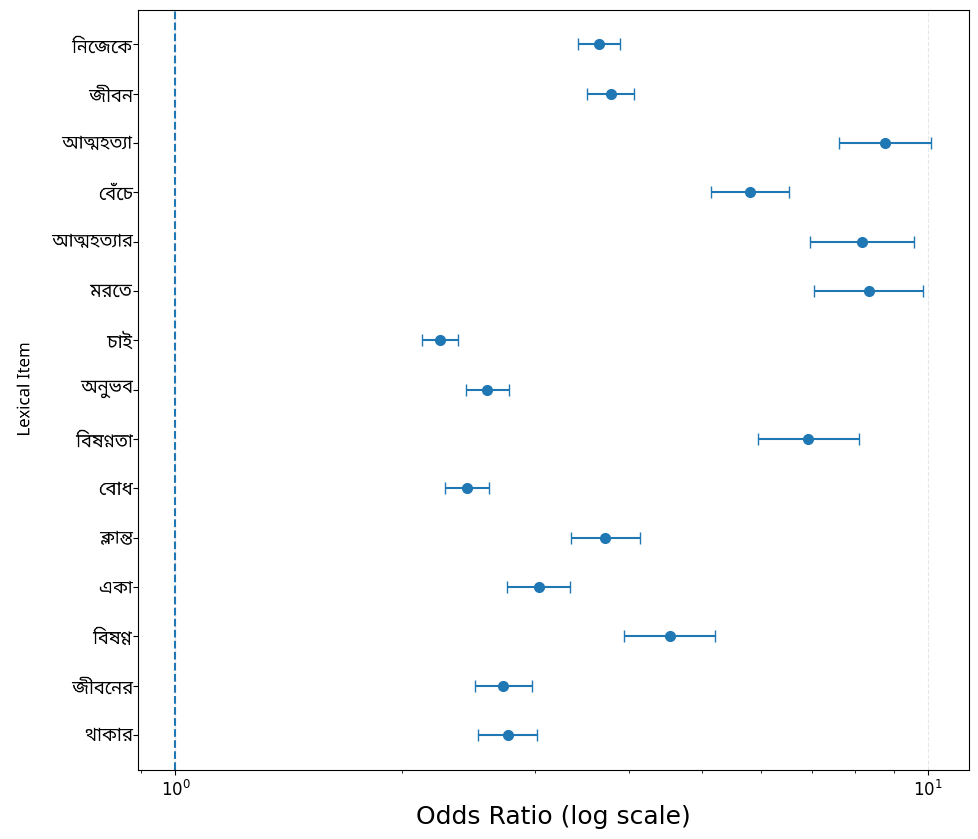

In [ ]:
# ============================================================
# CELL 39 — ODDS RATIO FOREST PLOT
# WITH BANGLA RENDERING
# ============================================================


# ============================================================
# IMPORT
# ============================================================
import matplotlib.pyplot as plt
import bangla_render as br
import os
import matplotlib
import matplotlib.font_manager
import glob
import numpy as np


# ============================================================
# INSTALL AND INITIALIZE BANGLA FONT
# ============================================================
# Install Noto Sans Bengali font
!apt-get install -y fonts-noto-core


# ============================================================
# FIND NOTO SANS BENGALI FONT
# ============================================================
font_files = glob.glob(
    '/usr/share/fonts/**/NotoSansBengali-Regular.ttf',
    recursive=True
)

if not font_files:
    raise FileNotFoundError(
        "NotoSansBengali-Regular.ttf not found after installing fonts-noto-core."
    )

font_path = font_files[0]

print(f"Found Noto Sans Bengali font at: {font_path}")


# ============================================================
# CLEAR MATPLOTLIB FONT CACHE
# ============================================================
cache_dir = matplotlib.get_cachedir()

font_cache_files = glob.glob(
    os.path.join(cache_dir, 'fontlist-v*.json')
)

for f in font_cache_files:
    try:
        os.remove(f)
    except:
        pass


# ============================================================
# ADD BANGLA FONT TO MATPLOTLIB
# ============================================================
matplotlib.font_manager.fontManager.addfont(font_path)


# ============================================================
# INITIALIZE BANGLA RENDERER
# ============================================================
br.init_renderer()


# ============================================================
# DATA
# ============================================================
forest_df =  top15_lexical.copy()

# Sort by Odds Ratio
forest_df = forest_df.sort_values(
    "Chi2",
    ascending=True
).reset_index(drop=True)



# ============================================================
# CREATE FIGURE
# ============================================================
fig, ax = plt.subplots(
    figsize=(11, 10)
)


# ============================================================
# Y POSITIONS
# ============================================================
y = np.arange(
    len(forest_df)
)


# ============================================================
# ERROR BAR VALUES
# ============================================================
lower_error = (
    forest_df["Odds_Ratio"]
    - forest_df["CI_Lower"]
)

upper_error = (
    forest_df["CI_Upper"]
    - forest_df["Odds_Ratio"]
)


# ============================================================
# FOREST PLOT
# ============================================================
ax.errorbar(
    forest_df["Odds_Ratio"],
    y,
    xerr=[
        lower_error,
        upper_error
    ],
    fmt="o",
    markersize=7,
    capsize=4,
    linewidth=1.5
)


# ============================================================
# REFERENCE LINE
# Odds Ratio = 1
# ============================================================
ax.axvline(
    1,
    linestyle="--",
    linewidth=1.5
)


# ============================================================
# BANGLA Y-AXIS TICK LABELS
# ============================================================
br.set_bangla_yticks(
    ax,
    y,
    forest_df["Word"].astype(str).tolist(),
    font_path=font_path,
    font_size=30
)


# ============================================================
# Y-AXIS TICK SETTINGS
# ============================================================
ax.tick_params(
    axis="y",
    labelsize=16
)


# ============================================================
# X-AXIS — LOG SCALE
# ============================================================
ax.set_xscale(
    "log"
)


# ============================================================
# X-AXIS LABEL
# ============================================================
ax.set_xlabel(
    "Odds Ratio (log scale)",
    fontsize=18
)


# ============================================================
# BANGLA Y-AXIS LABEL
# ============================================================
br.set_bangla_ylabel(
    ax,
    "Lexical Item",
    font_path=font_path,
    fontsize=30
)


# ============================================================
# BANGLA TITLE
# ============================================================
# br.set_bangla_title(
#     ax,
#     "Depression-Associated Lexical Items",
#     font_path=font_path,
#     fontsize=30
# )


# ============================================================
# X-AXIS TICK LABEL SIZE
# ============================================================
ax.tick_params(
    axis="x",
    labelsize=12
)


# ============================================================
# GRID
# ============================================================
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)


# ============================================================
# AUTOMATIC BANGLA LAYOUT
# ============================================================
br.apply_bangla_layout(
    fig,
    auto=True
)


# ============================================================
# SAVE HIGH-RESOLUTION FIGURE
# ============================================================
plt.savefig(
    "figure_7_odds_ratio_forest.png",
    dpi=750,
    bbox_inches="tight"
)


# ============================================================
# SHOW
# ============================================================
plt.show()

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-noto-core is already the newest version (20201225-2).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
Found Noto Sans Bengali font at: /usr/share/fonts/truetype/noto/NotoSansBengali-Regular.ttf


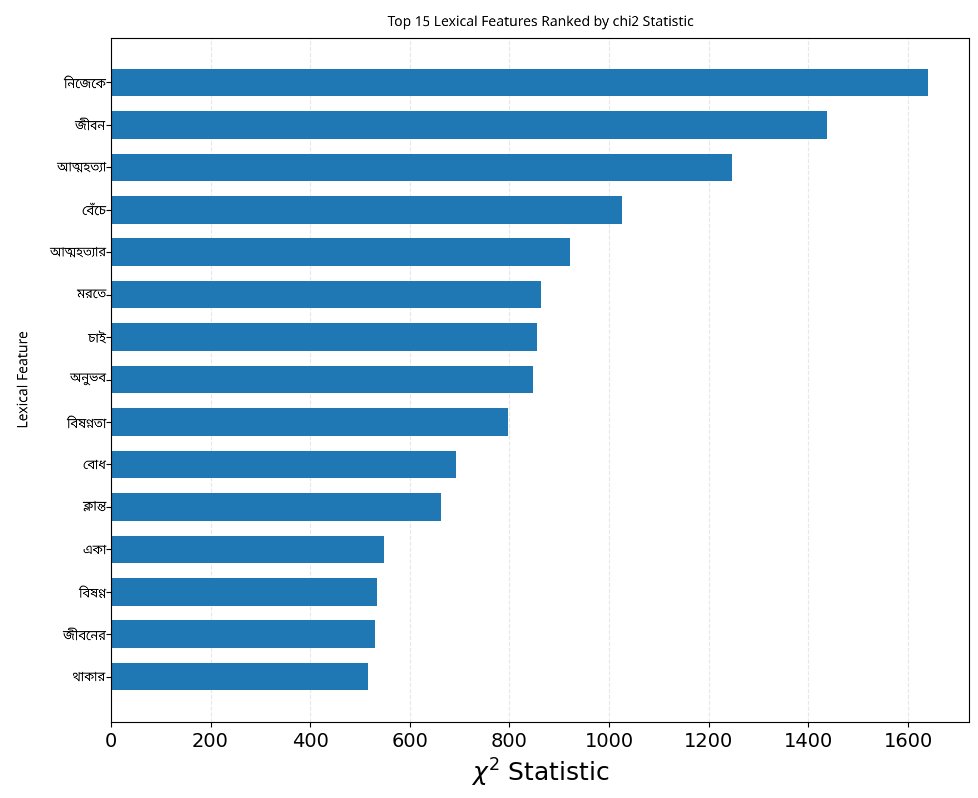

In [ ]:
# ============================================================
# CELL 39 — TOP 15 LEXICAL FEATURES BY CHI-SQUARE STATISTICS
# WITH BANGLA RENDERING
# ============================================================

# ============================================================
# IMPORT
# ============================================================
import matplotlib.pyplot as plt
import bangla_render as br
import os
import matplotlib
import matplotlib.font_manager
import glob
import numpy as np


# ============================================================
# INSTALL NOTO SANS BENGALI FONT
# ============================================================
!apt-get install -y fonts-noto-core


# ============================================================
# FIND NOTO SANS BENGALI FONT
# ============================================================
font_files = glob.glob(
    '/usr/share/fonts/**/NotoSansBengali-Regular.ttf',
    recursive=True
)

if not font_files:
    raise FileNotFoundError(
        "NotoSansBengali-Regular.ttf not found."
    )

font_path = font_files[0]

print(f"Found Noto Sans Bengali font at: {font_path}")


# ============================================================
# CLEAR MATPLOTLIB FONT CACHE
# ============================================================
cache_dir = matplotlib.get_cachedir()

font_cache_files = glob.glob(
    os.path.join(cache_dir, 'fontlist-v*.json')
)

for f in font_cache_files:
    try:
        os.remove(f)
    except:
        pass


# ============================================================
# ADD BANGLA FONT
# ============================================================
matplotlib.font_manager.fontManager.addfont(font_path)


# ============================================================
# INITIALIZE BANGLA RENDERER
# ============================================================
br.init_renderer()


# ============================================================
# DATA
# ============================================================
# Use the top 15 lexical features
chi2_df = top15_lexical.copy()

# Sort by Chi-square for horizontal ranking
chi2_df = chi2_df.sort_values(
    "Chi2",
    ascending=True
).reset_index(drop=True)


# ============================================================
# CREATE FIGURE
# ============================================================
fig, ax = plt.subplots(
    figsize=(11, 9)
)


# ============================================================
# Y POSITIONS
# ============================================================
y = np.arange(
    len(chi2_df)
)


# ============================================================
# HORIZONTAL BAR CHART
# ============================================================
ax.barh(
    y,
    chi2_df["Chi2"],
    height=0.65
)


# ============================================================
# BANGLA Y-AXIS TICK LABELS
# ============================================================
br.set_bangla_yticks(
    ax,
    y,
    chi2_df["Word"].astype(str).tolist(),
    font_path=font_path,
    font_size=25
)


# ============================================================
# Y-AXIS LABEL
# ============================================================
br.set_bangla_ylabel(
    ax,
    "Lexical Feature",
    font_path=font_path,
    fontsize=25
)


# ============================================================
# X-AXIS LABEL
# ============================================================
ax.set_xlabel(
    r"$\chi^2$ Statistic",
    fontsize=18
)


# ============================================================
# TITLE
# ============================================================
br.set_bangla_title(
    ax,
    r"Top 15 Lexical Features Ranked by chi2 Statistic",
    font_path=font_path,
    fontsize=25
)


# ============================================================
# X-AXIS TICK SIZE
# ============================================================
ax.tick_params(
    axis="x",
    labelsize=14
)


# ============================================================
# GRID
# ============================================================
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)


# ============================================================
# ADD CHI-SQUARE VALUES AT END OF BARS
# ============================================================
# for i, value in enumerate(chi2_df["Chi2"]):

#     ax.text(
#         value,
#         i,
#         # f" {value:.2f}",
#         va="center",
#         fontsize=10
#     )


# ============================================================
# AUTOMATIC BANGLA LAYOUT
# ============================================================
br.apply_bangla_layout(
    fig,
    auto=True
)


# ============================================================
# SAVE HIGH-RESOLUTION FIGURE
# # ============================================================
# plt.savefig(
#     "figure_7_top15_lexical_chi2.png",
#     dpi=850,
#     bbox_inches="tight"
# )


# ============================================================
# SHOW
# ============================================================
plt.show()